# Polynomial regression

Let us train polynomial regressors. Given data $(x_1,y_1),\ldots, (x_n,y_n)$ we search for polynomial regressors $f$ such that $$\sum_{i=1} (y_i-f(x_i))^2$$ becomes small.

First we do some of the necessary imports.

In [3]:
import numpy as np  # for general scientific computing
import matplotlib.pyplot as plt # plotting
import sklearn.linear_model # linear regression
import sklearn.preprocessing # for polynomial regression

We generate a small training and test set. Both sets come from the quadratic function $1.5x^2-2x+1$, with a little bit of random noise added. To illustrate both sets we plot them, as well as the quadratic function.

We notice that the estimators of *scikit learn* expect the training set to have a particular format: a list (or rather an array) of (multidimensional) data vectors. Because of that the estimators will raise an error if the training set is 1-dimensional. Consequently, we need to <code>reshape</code> the data. That is, we turn 1-dimensional data into 2-dimensional data. Let me demonstrate.

In [4]:
one_dim=np.array([1.,2.,42.])
one_dim

array([ 1.,  2., 42.])

In [5]:
one_dim.reshape(-1,1)

array([[ 1.],
       [ 2.],
       [42.]])

Now let's generate the training set consisting of data <code>x_train</code> and target values <code>y_train</code>, and the test set consisting of <code>x_test</code> and <code>y_test</code>.

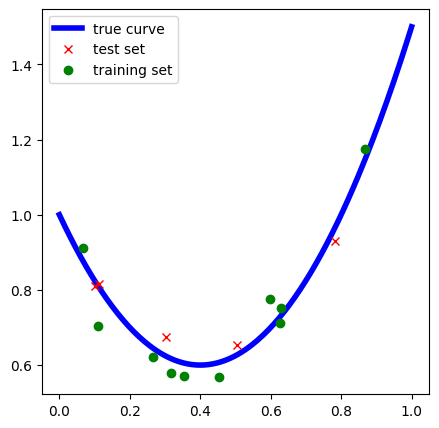

In [6]:
def true_function(x):
    return 2.5*x**2-2*x+1

def draw_points(number):
    np.random.seed(42*number)
    x = np.random.random(number)
    noise = np.random.normal(scale=0.05,size=number)
    y = true_function(x) + noise
    return x.reshape(-1,1),y # x reshaped because training set cannot be 1-dim

training_size = 10
x_train,y_train=draw_points(training_size)

test_size = 5
x_test,y_test = draw_points(test_size)

xx=np.linspace(0,1,200)
yy_true=true_function(xx)
fig,ax=plt.subplots(figsize=(5,5))
ax.plot(xx,yy_true,"b-",label="true curve",linewidth=4)
ax.plot(x_test.flat,y_test,"rx",label="test set")
ax.plot(x_train.flat,y_train,"go",label="training set")
ax.legend()
plt.show()

Next, we train a linear regression. For this, we first instantiate a <code>LinearRegression</code> object. Then it needs to be trained.

In [7]:
lin_reg=sklearn.linear_model.LinearRegression()
lin_reg.fit(x_train,y_train)

LinearRegression()

Once trained, we can <code>predict</code> new values. The method <code>predict</code> expects the $x$-values in the same format as the training set, ie, a list of(multidimensional) data points.

Because we have 1-dimensional $x$ we even need to put the data into two square brackets. Let's predict two values.

In [8]:
lin_reg.predict([[1],[2]])

array([0.92269465, 1.2482328 ])

Linear regression is not very interesting. Let's do quadratic regression. We already know that quadratic regression is just linear regression with a modified training set. In *scikit learn* we can easily compute features of any degree with <code>PolynomialFeatures</code>. In the same way that estimators need to be fit first, this is also the case for <code>PolynomialFeatures</code>. <code>fit</code> does not do much here: It simply memorises the dimension of the data. Instead of a <code>predict</code> method, we have here a <code>transform</code> method. Let's have a look.

In [13]:
quad_features=sklearn.preprocessing.PolynomialFeatures(degree=2)
x_demo=np.array([0,1,2,3]).reshape(-1,1) # reshape because estimator expects multidim training set
quad_features.fit(x_demo)
quad_features.transform(x_demo)

array([[1., 0., 0.],
       [1., 1., 1.],
       [1., 2., 4.],
       [1., 3., 9.]])

We see that the data <code>[2]</code> turns into <code>[1,2,4]</code>, ie, constant term, linear term and quadratic term, as expected.

Next, we can plug the new, transformed training set into a linear regression, and obtain a quadratic regressor.

In [14]:
reg=sklearn.linear_model.LinearRegression()
reg.fit(quad_features.transform(x_train),y_train)

LinearRegression()

What is a bit annoying: If we now want to do predictions, we first need to <code>transform</code> the $x$-values via <code>quad_features</code> and then call <code>predict</code> on <code>reg</code>:

In [15]:
reg.predict(quad_features.transform([[1],[3]]))

array([ 1.57051822, 18.39542361])

Because that is so annyoing, *scikit learn* has the class <code>Pipeline</code> that allows to chain any number of transformators and a <code>predictor</code>. Once the pipeline is defined, it can be used like a normal regressor, ie, we can call <code>fit</code> and also <code>predict</code> on it. Here's how that works.

In [16]:
import sklearn.pipeline
quad_features=sklearn.preprocessing.PolynomialFeatures(degree=2)
reg=sklearn.linear_model.LinearRegression()
### this what we want to chain:
steps=[('quadratic features',quad_features),('linear regression',reg)] # always pairs (name, estimator)
quad_pipe=sklearn.pipeline.Pipeline(steps)
quad_pipe.fit(x_train,y_train)

Pipeline(steps=[('quadratic features', PolynomialFeatures()),
                ('linear regression', LinearRegression())])

The whole pipeline is now trained and can be used for prediction.

In [17]:
quad_pipe.predict([[1],[3]])

array([ 1.57051822, 18.39542361])

### Train degree 10 regressor ###

In the same way as above, define a regressor of degree 10 with a pipeline and train it on the training set. The <code>Pipeline</code> object that encapsulates the regressor should be called <code>ten_pipe</code>.

In [18]:

ten_features=sklearn.preprocessing.PolynomialFeatures(degree=10)
steps_ten=[('10th degree features',ten_features),('linear regression',reg)]
ten_pipe=sklearn.pipeline.Pipeline(steps_ten)
ten_pipe.fit(x_train,y_train)


ten_pipe.predict([[1],[3]])

array([-4.87928674e+03, -1.75702538e+10])

Let's plot the result.

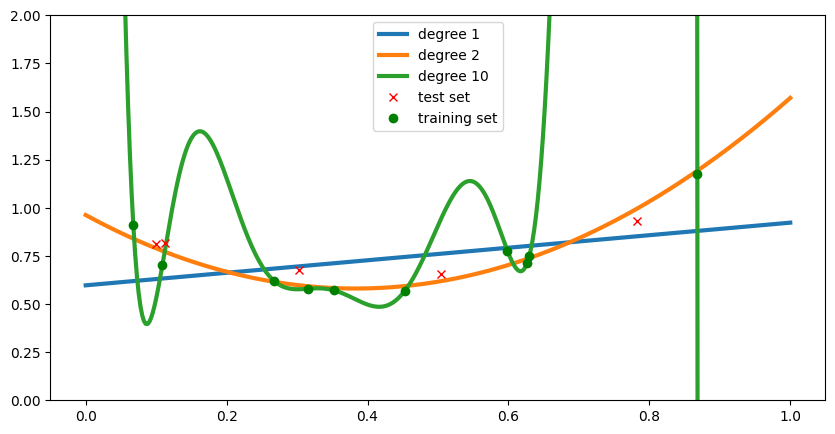

In [25]:

fig, ax = plt.subplots(figsize=(10, 5))
ax.set_ylim(0, 2)
xx = np.linspace(0, 1, 400)
estimators = [(1, lin_reg), (2, quad_pipe), (10, ten_pipe)]
for degree, estimator in estimators:
    ax.plot(xx, estimator.predict(xx.reshape(-1, 1)), linewidth=3, label="degree {}".format(degree))
ax.plot(x_test.flat, y_test, "rx", label="test set")
ax.plot(x_train.flat, y_train, "go", label="training set")
ax.legend()
plt.show()

Next, let's compute errors. For regression, we will use the *mean square error*, or mse:
$$
\text{mse}(y,y')=\frac{1}{n}\sum_{i=1}^n(y_i-y'_i)^2
$$

The mean square error is implemented as function <code>mean_squared_error</code> in package <code>sklearn.metrics</code>.

In [26]:
import sklearn.metrics

mse=sklearn.metrics.mean_squared_error
y1=[1,1,1]
y2=[1.1,0.9,1.1]
mse(y1,y2)

0.010000000000000009

### Errors ###


We now compute the training and test error for the three regressor we have trained above.

In [27]:
### insert your code here ###

lin_error_test = mse(lin_reg.predict(x_test), y_test)
lin_error_tr = mse(lin_reg.predict(x_train), y_train)
quad_error_test = mse(quad_pipe.predict(x_test), y_test)
quad_error_tr = mse(quad_pipe.predict(x_train), y_train)
ten_error_test = mse(ten_pipe.predict(x_test), y_test)
ten_error_train = mse(ten_pipe.predict(x_train), y_train)


print("Linear training error: {}".format(lin_error_tr))
print("Linear error: {}".format(lin_error_test))
print("Quadratic training error: {}".format(quad_error_tr))
print("Quadratic error: {}".format(quad_error_test))
print("10th degree training error: {}".format(ten_error_train))
print("10th degree error: {}".format(ten_error_test))

Linear training error: 0.025749152622868653
Linear error: 0.016783289005474343
Quadratic training error: 0.0017978010868627873
Quadratic error: 0.002812534657437764
10th degree training error: 1.765902996748054e-20
10th degree error: 677.3621161203631


### Interpretation ###


As we increase the degree, the capacity of our model becomes huge, thus making it easy for the algorithm to overfit, i.e. the classificator achieves good training results, but the gap between test and training is too big, indicating that the distribution was not actually learnt.

